# 数字123：ランク512から下げて画質と計算時間を検証

前回のランク384では初期複素場誤差1.22%、ランク512では0.172%でした。今回は **384、400〜500（10刻み）、512** を比較します。43モード、41本のThread、kr、係数、座標、開口は変更しません。保存済みランク512の親基底の列数だけを減らします。小ランク辞書を別途学習した場合の結果ではありません。

1. 保存済み直接場と比較し、各ランクの初期複素場誤差・強度誤差・パワー比・場生成時間を記録します。
2. 複素場相対L2誤差1%以下、強度相対L2誤差3%以下を満たす最小の**候補**を選びます。絶対的な最小ランクを確定するものではありません。
3. 選んだランクでCGH化と伝搬を実行し、直接法との再生強度のSSIM・PSNR・相対L2誤差、目標との誤差を比較します。初期場の合格だけで再生像の一致とは判断しません。

低ランクのコア・因子を事前に一度だけ連続配列へ整えます。この準備時間は別記録し、オンライン場生成に含めません。全ランクを1回ウォームアップ後、3回測定した中央値で比較します。Threadごとの配列の詰め直しを避ける修正版です。旧結果は上書きしません。

初期評価では直接場を読み込むため、直接法の新しい生成時間は測りません。画質評価は条件が一致する保存済みCGH・伝搬結果を再利用できます。その結果内の旧計算時間と、今回の中央値を混同しないでください。


In [2]:
import importlib
import json
from pathlib import Path
from IPython.display import Image, display
import lsh_digit1_theory as theory
import lsh_digit1_proposed as proposed
import lsh_digits123_rank_audit as rank_audit
theory = importlib.reload(theory)
proposed = importlib.reload(proposed)
rank_audit = importlib.reload(rank_audit)

# ランク512で検証済みの123を基準にする。krやThread数は固定。
REFERENCE_DIR = Path('lsh_digits123_rank_verified_outputs_rank512_parent512_v1')
AUDIT_DIR = Path('lsh_digits123_rank_refinement_outputs_v2_contiguous')
RANKS = (384, *range(400, 501, 10), 512)
MAX_COMPLEX_ERROR = 0.01    # 初期複素場の相対L2：1%
MAX_INTENSITY_ERROR = 0.03  # 初期強度の相対L2：3%
TIMING_REPEATS = 3
TIMING_WARMUPS = 1
RUN_FINITE_VALIDATION = True  # 合格候補のCGH・伝搬まで実行
VALIDATION_VERSION = 'v1'

source = json.loads((REFERENCE_DIR/'summary.json').read_text(encoding='utf-8'))
config = theory.Digit1Config(**source['config'])
if source.get('rank') != 512 or source.get('library_parent_rank') != 512:
    raise ValueError('ランク512・親ランク512の検証済み結果を指定してください。')
if max(RANKS) != 512:
    raise ValueError('同じ親基底を使うため、候補には比較基準の512を残してください。')
print('候補ランク:', RANKS)
print('オンライン実装:', proposed.ONLINE_IMPLEMENTATION_VERSION)
print('各ランクのウォームアップ回数 / 測定回数:', TIMING_WARMUPS, TIMING_REPEATS)
print('基準ランク512の再生強度誤差:', source['metrics']['cgh_sheet_proposed_vs_direct']['intensity_relative_l2'])
print('既存のランク512辞書を再利用します。初期評価の直接場は保存結果を使用します。')


候補ランク: (384, 400, 410, 420, 430, 440, 450, 460, 470, 480, 490, 500, 512)
オンライン実装: contiguous_core_matvec_v2
各ランクのウォームアップ回数 / 測定回数: 1 3
基準ランク512の再生強度誤差: 0.0016376543319478185
既存のランク512辞書を再利用します。初期評価の直接場は保存結果を使用します。


Rank 384: complex error=1.222%, intensity error=0.250%, power/direct=0.9996, field median=1.1292s (3 repeats)
Rank 400: complex error=1.139%, intensity error=0.232%, power/direct=0.9997, field median=1.1598s (3 repeats)
Rank 410: complex error=1.109%, intensity error=0.225%, power/direct=0.9997, field median=1.3983s (3 repeats)
Rank 420: complex error=1.093%, intensity error=0.221%, power/direct=0.9997, field median=1.3979s (3 repeats)
Rank 430: complex error=1.085%, intensity error=0.220%, power/direct=0.9997, field median=1.4759s (3 repeats)
Rank 440: complex error=1.075%, intensity error=0.219%, power/direct=0.9997, field median=1.3721s (3 repeats)
Rank 450: complex error=0.790%, intensity error=0.137%, power/direct=0.9998, field median=1.4356s (3 repeats)
Rank 460: complex error=0.784%, intensity error=0.136%, power/direct=0.9998, field median=1.5406s (3 repeats)
Rank 470: complex error=0.779%, intensity error=0.137%, power/direct=0.9998, field median=1.5479s (3 repeats)
Rank 480: 

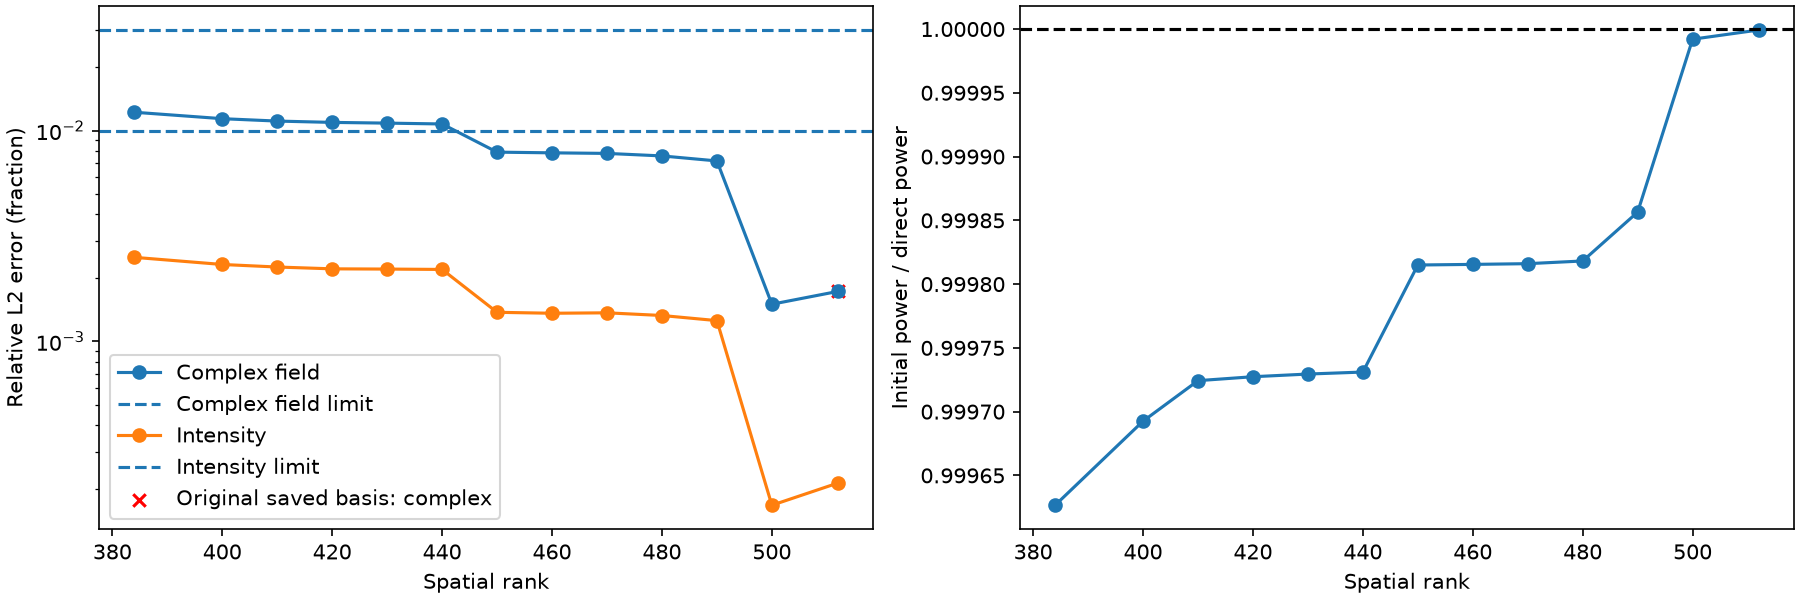

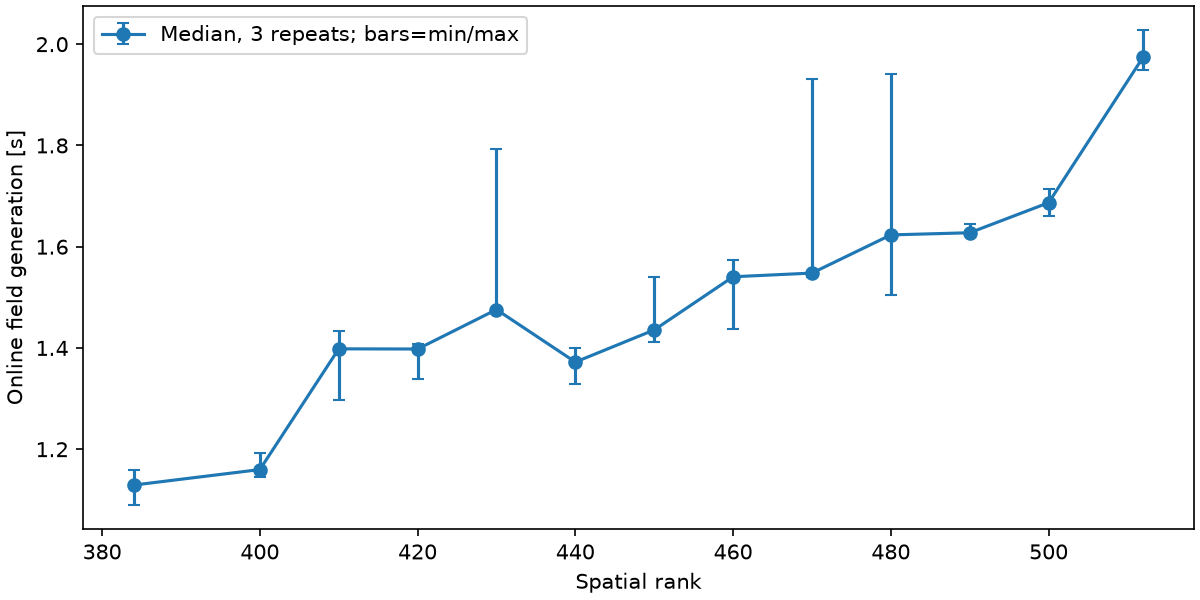

rank | 複素場誤差[%] | 強度誤差[%] | パワー比 | 場生成[秒・中央値] | 初期場合格
 384 |       1.22156 |     0.25029 |  0.99963 |           1.1292 | 不合格
 400 |       1.13859 |     0.23152 |  0.99969 |           1.1598 | 不合格
 410 |       1.10924 |     0.22517 |  0.99972 |           1.3983 | 不合格
 420 |       1.09335 |     0.22074 |  0.99973 |           1.3979 | 不合格
 430 |       1.08469 |     0.22018 |  0.99973 |           1.4759 | 不合格
 440 |       1.07474 |     0.21931 |  0.99973 |           1.3721 | 不合格
 450 |       0.78994 |     0.13730 |  0.99981 |           1.4356 | 合格
 460 |       0.78398 |     0.13587 |  0.99982 |           1.5406 | 合格
 470 |       0.77916 |     0.13653 |  0.99982 |           1.5479 | 合格
 480 |       0.75801 |     0.13259 |  0.99982 |           1.6233 | 合格
 490 |       0.71769 |     0.12538 |  0.99986 |           1.6276 | 合格
 500 |       0.14998 |     0.01668 |  0.99999 |           1.6869 | 合格
 512 |       0.17249 |     0.02125 |  1.00000 |           1.9749 | 合格
合格した最小の候補: 450
初期評価の数値: C:\Use

In [3]:
# 各候補を同じ親基底から復元する。CGH・伝搬はまだ実行しない。
audit = rank_audit.run_rank_audit(REFERENCE_DIR, AUDIT_DIR, RANKS,
    max_complex_error=MAX_COMPLEX_ERROR, max_intensity_error=MAX_INTENSITY_ERROR,
    timing_repeats=TIMING_REPEATS, timing_warmups=TIMING_WARMUPS)
display(Image(filename=str(AUDIT_DIR/'rank_initial_error.png'), width=1000))
display(Image(filename=str(AUDIT_DIR/'rank_field_timing.png'), width=900))
print('rank | 複素場誤差[%] | 強度誤差[%] | パワー比 | 場生成[秒・中央値] | 初期場合格')
for row in audit['cases']:
    passed = (row['complex_relative_l2'] <= MAX_COMPLEX_ERROR
              and row['intensity_relative_l2'] <= MAX_INTENSITY_ERROR)
    print(f"{row['rank']:4d} | {100*row['complex_relative_l2']:13.5f} | "
          f"{100*row['intensity_relative_l2']:11.5f} | {row['power_ratio_vs_direct']:8.5f} | "
          f"{row['field_seconds']:16.4f} | {'合格' if passed else '不合格'}")
print('合格した最小の候補:', audit['accepted_rank'])
print('初期評価の数値:', (AUDIT_DIR/'rank_scores.csv').resolve())
print('配列準備時間はlibrary_packing_seconds、各処理の中央値は同じCSV、反復値はsummary.jsonにあります。')
if audit['accepted_rank'] is None:
    print('合格なし。CGH・伝搬へは進みません。')
elif audit['accepted_rank'] == 512:
    print('今回の候補では512未満は合格しませんでした。512の保存済み伝搬結果を表示します。')


In [4]:
# 初期場が合格した最小候補を、CGH・伝搬で追加検証する。
# 小ランクでは直接場を新しくJ0から生成するため、この段階には時間がかかる。
validation_summary = None
output_dir = None
if not RUN_FINITE_VALIDATION:
    print('初期場評価まで。CGH・伝搬も評価する場合はRUN_FINITE_VALIDATION=True。')
elif audit['recommendation'] is None:
    print('合格ランクなし。CGH・伝搬は実行しません。')
else:
    rec = audit['recommendation']
    if (rec['rank'] == source['rank']
            and rec['library_parent_rank'] == source['library_parent_rank']
            and rec['library_path'] == source['library_path']):
        # 下げられなかった場合は同じ512を再計算しない。
        output_dir = REFERENCE_DIR
        validation_summary = source
    else:
        output_dir = Path(f"lsh_digits123_rank_refined_outputs_rank{rec['rank']}_parent{rec['library_parent_rank']}_{VALIDATION_VERSION}")
        if (output_dir/'summary.json').is_file() and (output_dir/'manifest.json').is_file():
            saved = json.loads((output_dir/'summary.json').read_text(encoding='utf-8'))
            valid = (saved.get('study') == 'digit1_direct_vs_projected_shared_core'
                and theory.config_payload(saved['config']) == theory.config_payload(config)
                and saved.get('rank') == rec['rank']
                and saved.get('library_parent_rank') == rec['library_parent_rank']
                and saved.get('seed') == rec['seed']
                and saved.get('library_path') == rec['library_path']
                and saved.get('mode_spacing_factor', 1) == rec['mode_spacing_factor']
                and saved.get('basis_strategy') == rec['basis_strategy'])
            if not valid:
                raise ValueError('保存結果が別条件です。VALIDATION_VERSIONを変更してください。')
            validation_summary = saved
        elif output_dir.exists() and any(output_dir.iterdir()):
            raise ValueError('途中結果があります。VALIDATION_VERSIONを変更してください。')
        else:
            validation_summary = proposed.run_comparison(output_dir, config,
                rank=rec['rank'], library_parent_rank=rec['library_parent_rank'],
                library_path=rec['library_path'], seed=rec['seed'],
                mode_spacing_factor=rec['mode_spacing_factor'], basis_strategy=rec['basis_strategy'],
                max_initial_complex_error=MAX_COMPLEX_ERROR, run_shift_diagnostics=True)
    initial = validation_summary['metrics']['initial_complex_proposed_vs_direct']
    if (initial['complex_relative_l2'] > MAX_COMPLEX_ERROR
            or initial['intensity_relative_l2'] > MAX_INTENSITY_ERROR):
        raise ValueError('最終比較の初期場が基準を満たしていません。結果を確認してください。')
    print('CGH・伝搬結果の保存先:', output_dir.resolve())


CGH・伝搬結果の保存先: C:\Users\kota-\Github\Project_new\research\lsh_digits123_rank_refined_outputs_rank450_parent512_v1


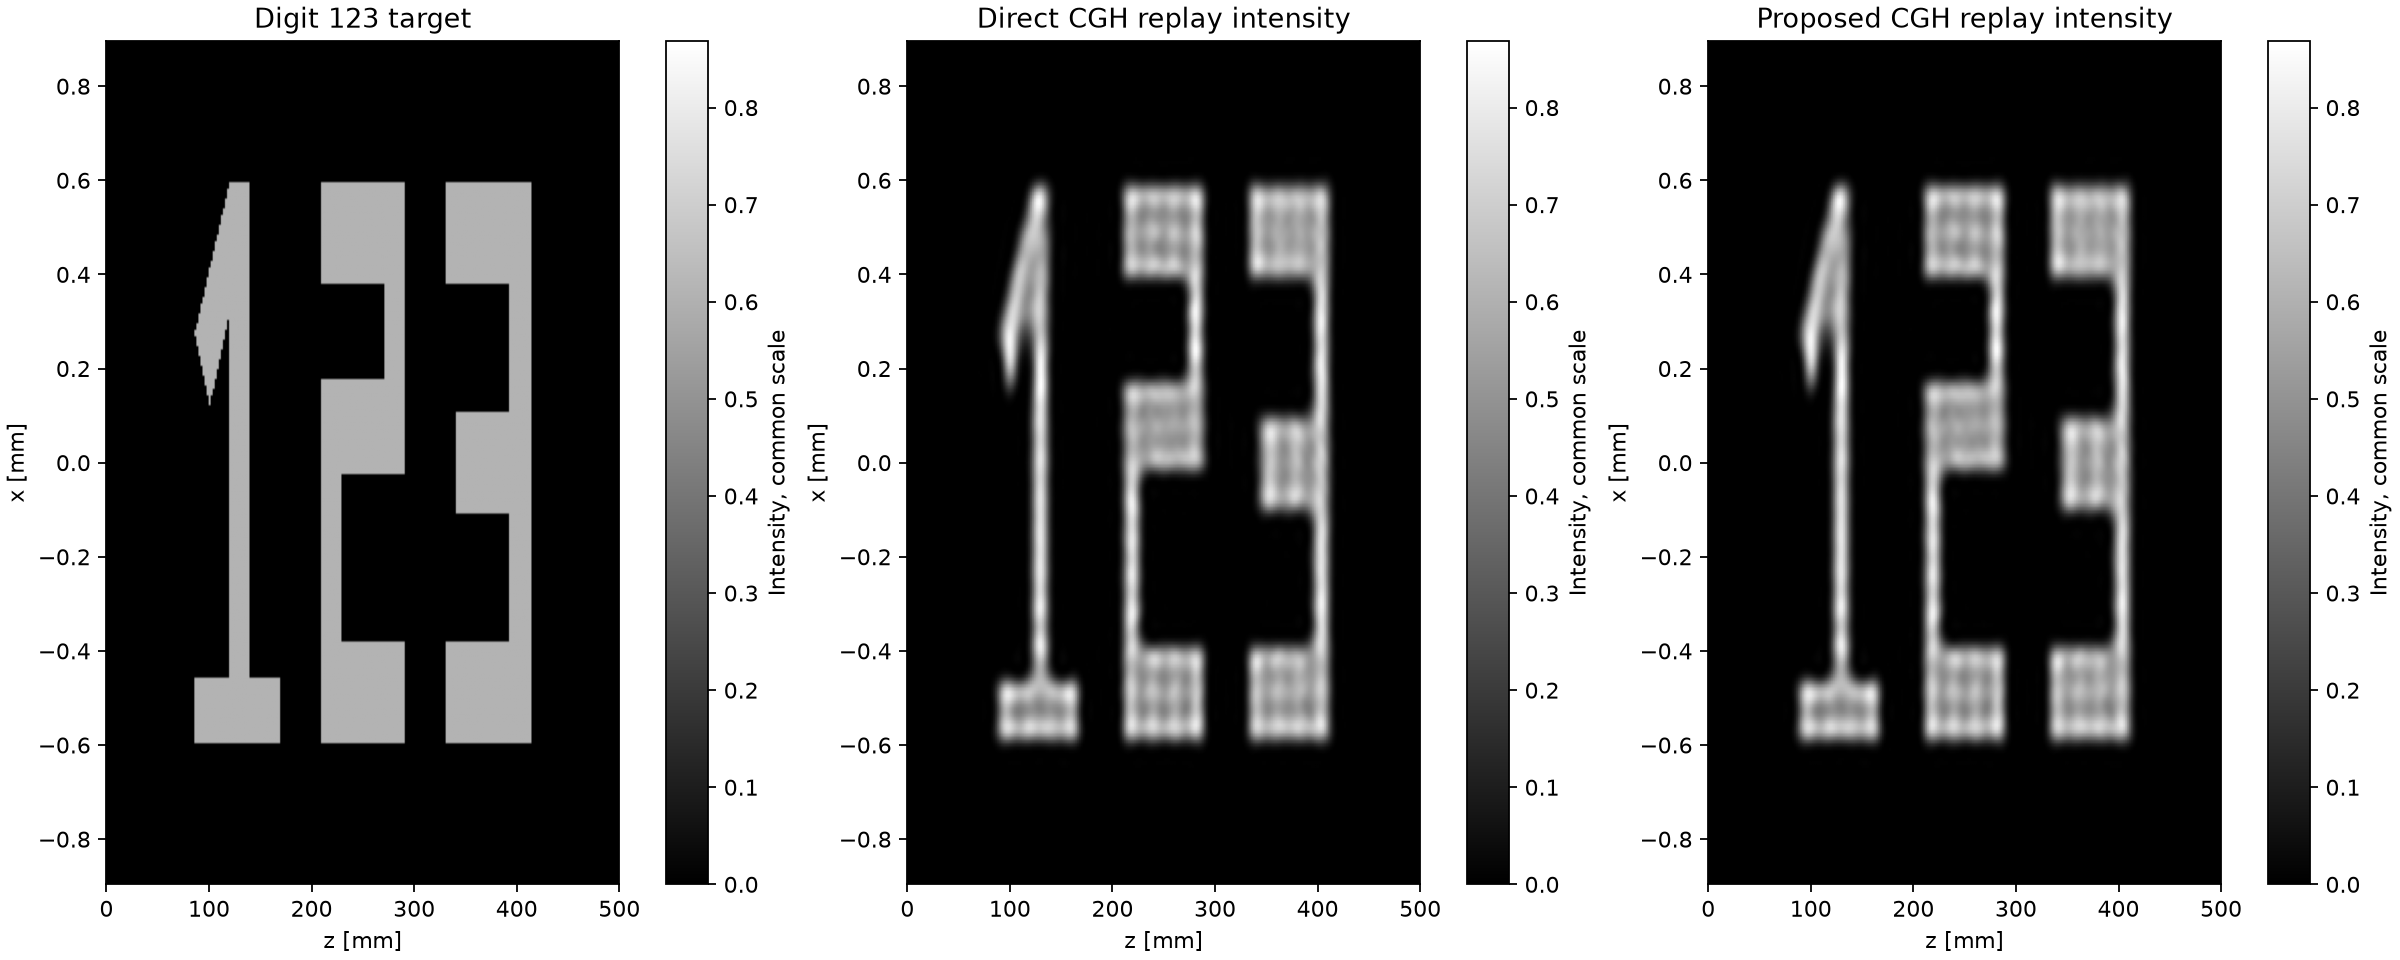

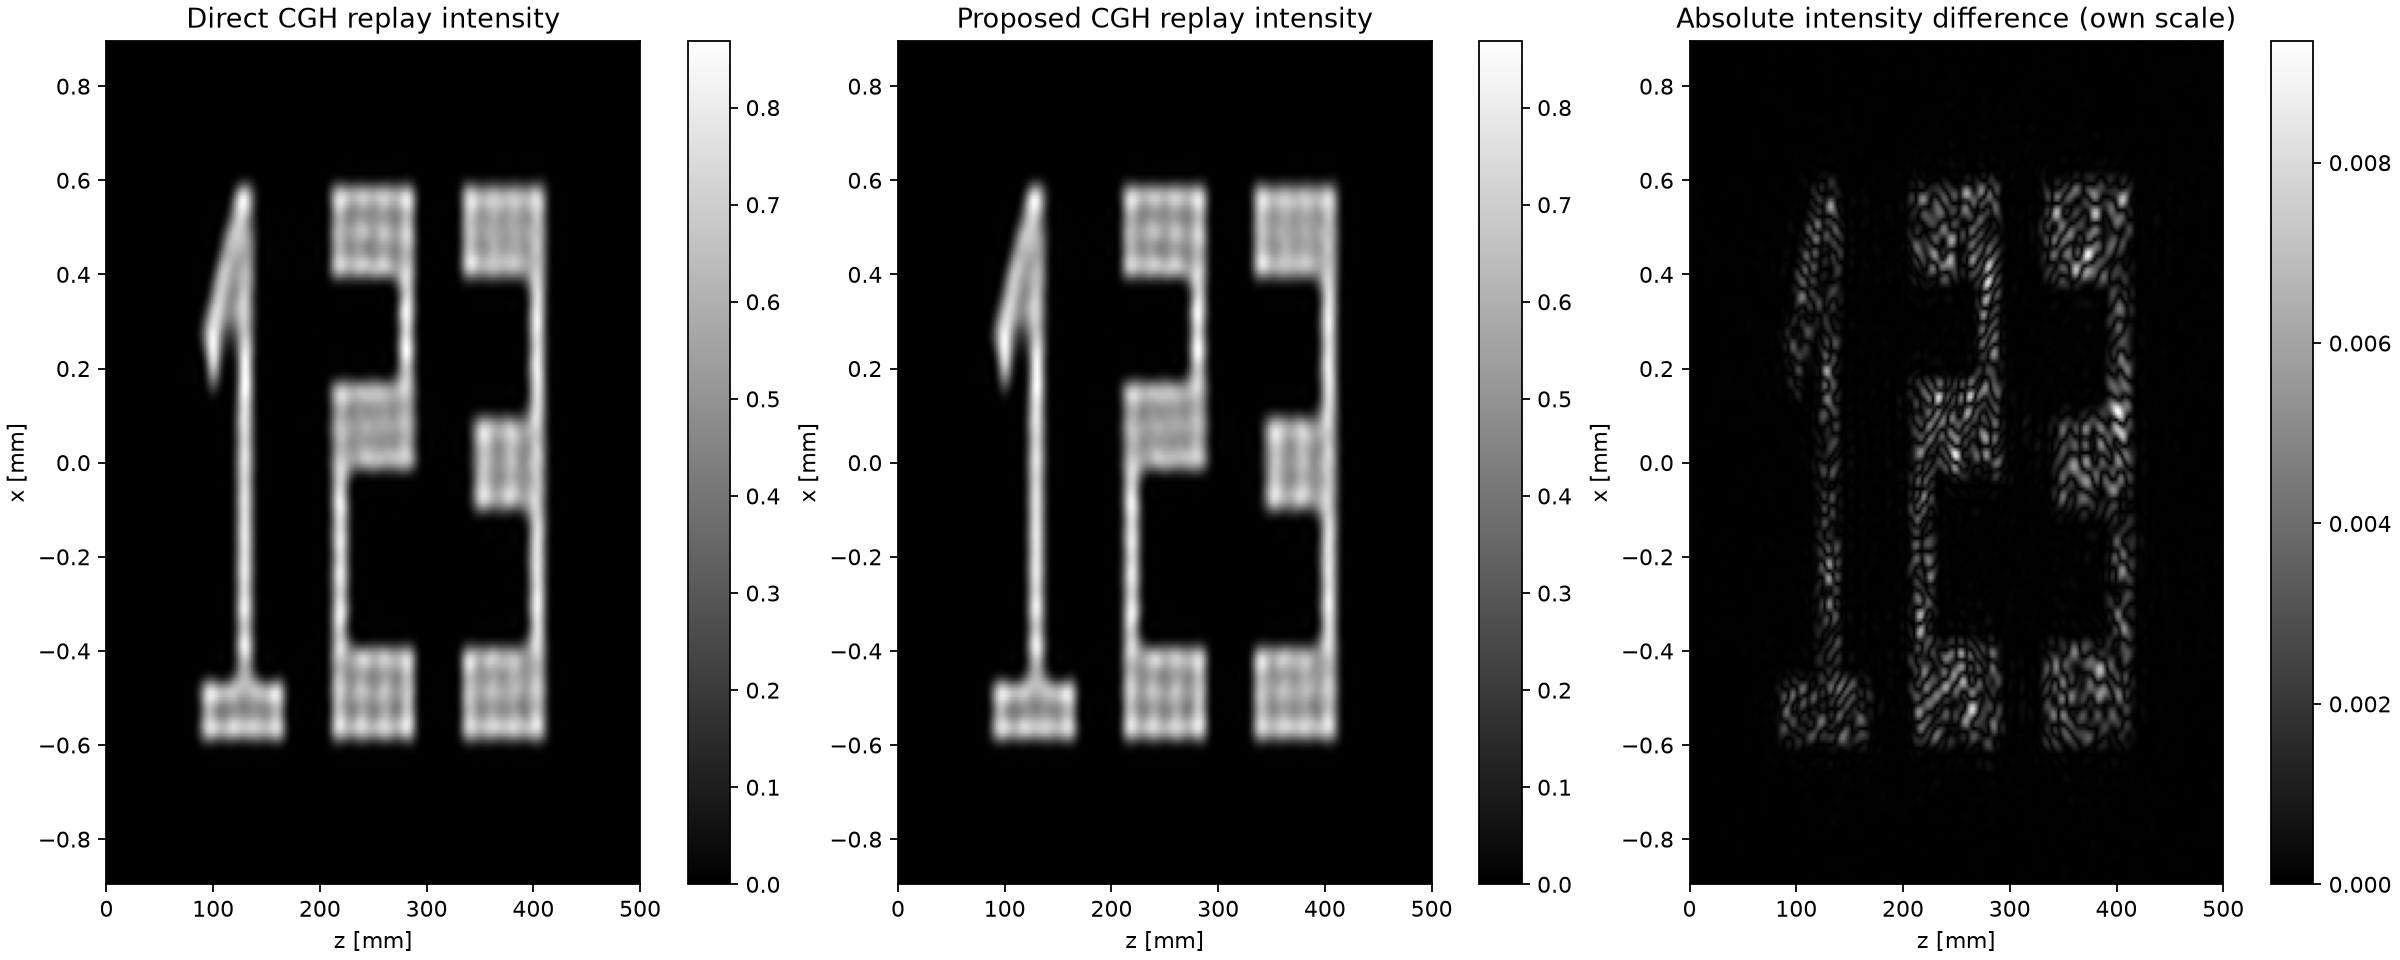

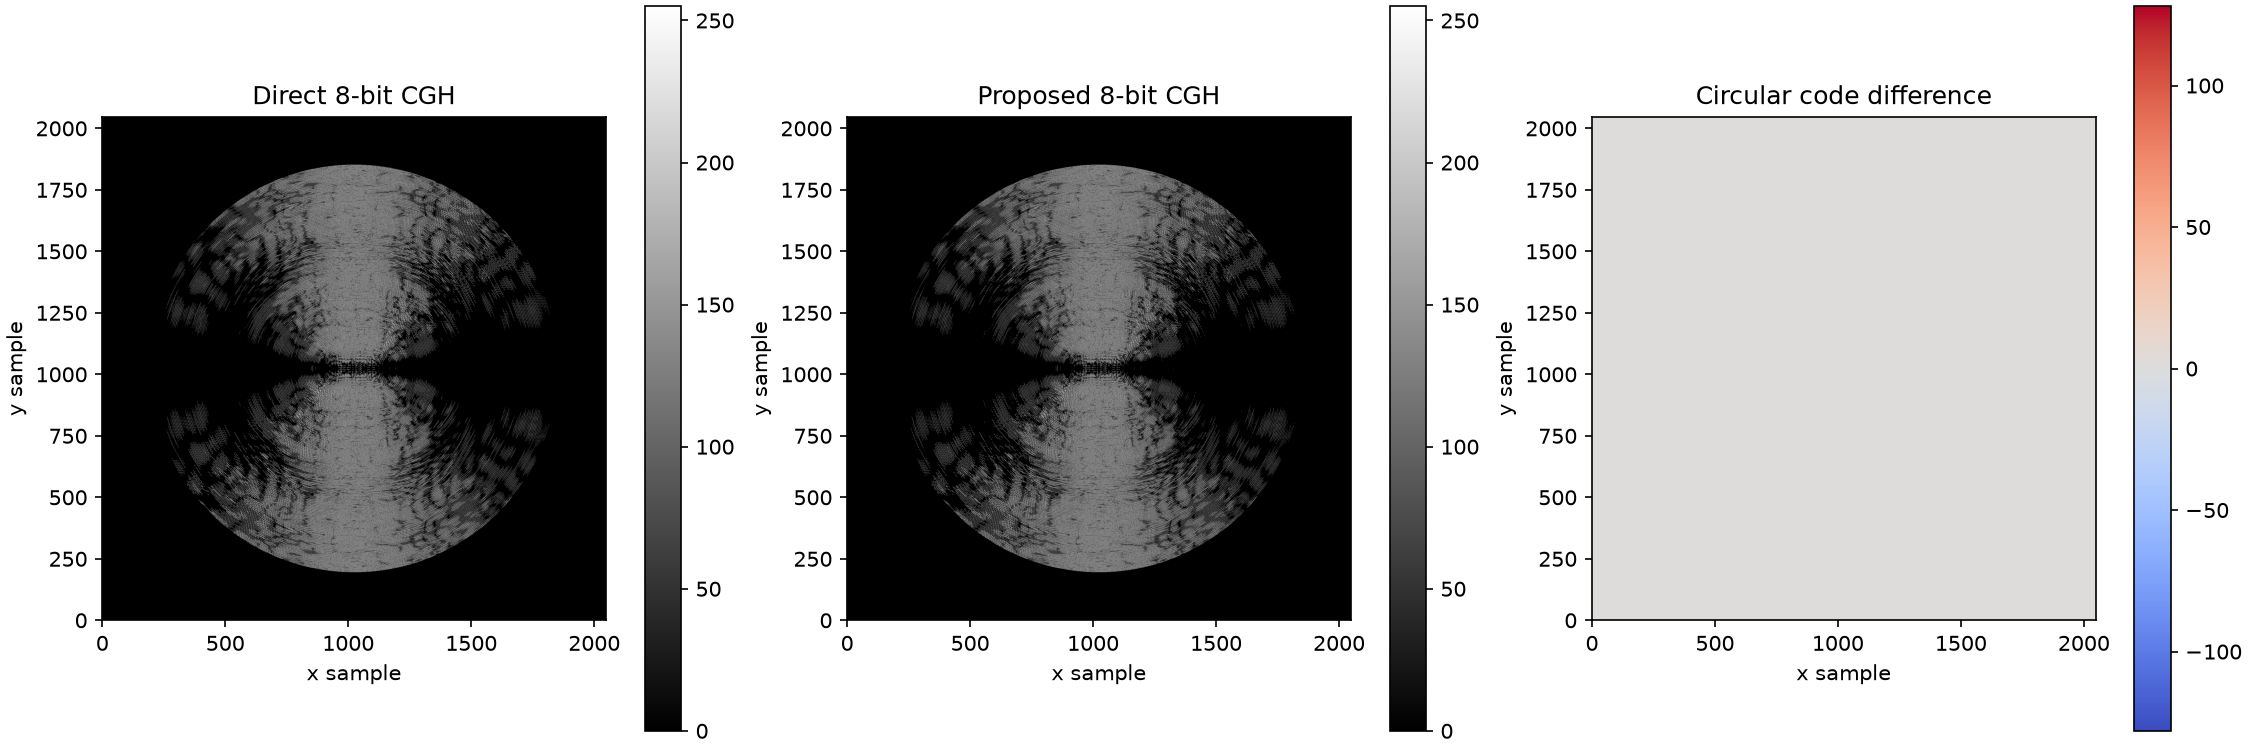

画質は伝搬比較の保存値。場生成時間は今回の初期場評価の中央値です。
ランク | 再生強度誤差[%] | 再生SSIM | 再生PSNR[dB] | 提案場生成[秒・中央値]
基準  512 |         0.16377 | 0.99998433 |       67.169 |              1.9749
今回  450 |         0.38430 | 0.99991688 |       59.760 |              1.4356
今回の直接法/目標: {'intensity_relative_l2': 0.32807586206627876, 'ssim': 0.7686011283733056, 'psnr_db': 16.97356560672406, 'snr_db': 9.680514426539856}
今回の提案法/目標: {'intensity_relative_l2': 0.3280626436618416, 'ssim': 0.7687436495825986, 'psnr_db': 16.973915574302993, 'snr_db': 9.68086439411879}
今回の初期場評価・時間内訳（各中央値）: {'rank': 450, 'basis': 'prefix_of_rank512', 'complex_relative_l2': 0.007899427634378928, 'intensity_relative_l2': 0.0013730303899941736, 'power_ratio_vs_direct': 0.9998149785885447, 'field_seconds': 1.435642700000244, 'field_seconds_min': 1.4114878000000317, 'field_seconds_max': 1.5398291000001336, 'library_packing_seconds': 0.033097100000304636, 'core_matrix_setup_seconds': 2.3000002329354174e-06, 'thread_core_weighting_seconds': 0.19866009999896

In [5]:
if validation_summary is not None:
    display(Image(filename=str(output_dir/'target_direct_proposed.png'), width=1200))
    display(Image(filename=str(output_dir/'cgh_sheet_comparison.png'), width=1200))
    display(Image(filename=str(output_dir/'cgh_mask_comparison.png'), width=1200))
    rows_by_rank = {row['rank']: row for row in audit['cases']}
    print('画質は伝搬比較の保存値。場生成時間は今回の初期場評価の中央値です。')
    print('ランク | 再生強度誤差[%] | 再生SSIM | 再生PSNR[dB] | 提案場生成[秒・中央値]')
    for label, result in [('基準', source), ('今回', validation_summary)]:
        metric = result['metrics']['cgh_sheet_proposed_vs_direct']
        seconds = rows_by_rank[result['rank']]['field_seconds']
        print(f"{label} {result['rank']:4d} | {100*metric['intensity_relative_l2']:15.5f} | "
              f"{metric['ssim']:.8f} | {metric['psnr_db']:12.3f} | {seconds:19.4f}")
    print('今回の直接法/目標:', validation_summary['metrics']['direct_cgh_sheet_vs_target'])
    print('今回の提案法/目標:', validation_summary['metrics']['proposed_cgh_sheet_vs_target'])
    print('今回の初期場評価・時間内訳（各中央値）:', rows_by_rank[validation_summary['rank']])
    print('CGH・伝搬比較を保存した時点の時間内訳（今回の中央値ではありません）:', validation_summary['timings_seconds'])
    print('詳細JSON:', (output_dir/'summary.json').resolve())
    print('修正版の時間・反復値:', (AUDIT_DIR/'summary.json').resolve())
    print('CGH再生・伝搬の画質と今回の場生成時間を確認して採用ランクを判断してください。')
else:
    print('この実行ではCGH・伝搬を評価していません。初期場の数値はrank_scores.csvにあります。')
